<a href="https://colab.research.google.com/github/eniyigena/ML-Teaching-/blob/main/CaseStudy_Spotify_DataScienceApplication_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Data Science Applications in Business - Session. Classification**
##**A Case Study of Spotify**

## **Data Description**

This is a description of the dataset including the generated target variable 'billboard'.

**Column name: column description**

1. 'id': identifier for track on spofity database  
2. 'name': name of the track  
3. 'artists':  artist(s) of the track  
4. 'billboard': target variable: 1 if target was on Billboard Hot 100 the year it was released, 0 otherwise  
5. 'year': year the track was released  
6. 'popularity':  how much the song is currently being streamed. Ranges from 0 (not streamed much) to 100 (streamed the most)  
7. 'duration_ms':  length of the song in milliseconds  
8. 'loudness':  measure of how loud the song is in decibels (dB)  
9. 'tempo':  number of beats per minute  
10. 'acousticness': Ranges from 0 to 1 with 1 being most acoustic  
11. 'danceability': Ranges from 0 to 1 with 1 being most danceable  
12. 'energy': Ranges from 0 to 1 with 1 being most energetic  
13. 'instrumentalness': Ranges from 0 to 1 with 1 being most acoustic and 0 being more vocal (like rap songs)  
14. 'liveness': Ranges from 0 to 1 with 1 being most live (0.8 probably indicates song is live)  
15. 'speechiness': Ranges from 0 to 1 with 1 being most wordy (0.66 probably indicates entirely spoken words)  
16. 'valence': Ranges from 0 to 1 with 1 being most positive and 0 being more negative/sad  
17. 'key': the estimated key of the overall track ranges from 0 to 11 indicating C, C#, D, D#, E, F, F#, G, G#, A, A#, B  
18. 'mode': 0 if minor and 1 if major  
19. 'explicit': 0 if no curse words, 1 if curse words  

## **Data Loading**

Note: It took more than 14 hours to create the target variable by matching the spotify and billboard datasets because the two datasets are relatively large. In this python Jupyter notebook, I did not include the code for creating the target variable, but I've used an already matched dataset.

In [ ]:
# import packages
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# read data
file = 'data.csv'
df = pd.read_csv(file)

print(df.shape)

df.head()

(97900, 19)


,id,name,artists,billboard,year,popularity,duration_ms,loudness,tempo,acousticness,danceability,energy,instrumentalness,liveness,speechiness,valence,key,mode,explicit
0,2AgMTn4RyRrI1uc3iXx4Xq,My Father's Gun,['Elton John'],0,1970,29,380667,-10.884,119.025,0.511,0.436,0.429,0.000103,0.104,0.0319,0.223,3,1,0
1,2hKxnhi2Eb3443AQbOnqNl,It Ain't Easy,['Three Dog Night'],0,1970,26,166707,-13.934,76.848,0.465,0.629,0.376,0.000000,0.235,0.0337,0.347,7,1,0
2,2nxSAQBvF6gDIwZmG6B9nO,I Should Be Proud,['Martha Reeves & The Vandellas'],0,1970,33,176573,-10.204,178.408,0.166,0.417,0.753,0.000000,0.269,0.1260,0.794,9,0,0
3,2vNuzzaFEPY2WGdYFhdeui,Where I Like To Stand,['Vashti Bunyan'],0,1970,26,141893,-19.189,117.630,0.990,0.600,0.107,0.011400,0.101,0.0525,0.732,0,0,0
4,439kdOcVhEp5gQ67eYNkKG,Available Space,['Ry Cooder'],0,1970,35,134067,-14.170,147.388,0.639,0.568,0.434,0.626000,0.229,0.0379,0.694,7,1,0


## **Data Understanding**

### **Summary Statistics**

In [ ]:
# summary statistics for numerical variables (mean, sd, min, max, quantiles)
df.loc[:,"year":"valence"].describe()

,year,popularity,duration_ms,loudness,tempo,acousticness,danceability,energy,instrumentalness,liveness,speechiness,valence
count,97900.000000,97900.000000,9.790000e+04,97900.000000,97900.000000,97900.000000,97900.000000,97900.000000,97900.000000,97900.000000,97900.000000,97900.000000
mean,1993.978233,44.409775,2.452751e+05,-9.453800,120.654448,0.297237,0.563071,0.605903,0.096984,0.202819,0.078042,0.542177
std,14.133003,12.824218,1.025097e+05,4.869018,30.006848,0.305817,0.173008,0.241284,0.241814,0.182954,0.091292,0.258705
min,1970.000000,16.000000,1.470800e+04,-60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1982.000000,35.000000,1.931070e+05,-11.952000,97.044750,0.028200,0.447000,0.438000,0.000000,0.092400,0.033700,0.336000
50%,1994.000000,44.000000,2.309330e+05,-8.514000,118.771500,0.179000,0.572000,0.630000,0.000059,0.128000,0.044100,0.551000
75%,2006.000000,53.000000,2.773070e+05,-5.957000,139.864000,0.521000,0.689000,0.804000,0.010500,0.257000,0.075100,0.758000
max,2018.000000,92.000000,5.403500e+06,3.744000,244.091000,0.996000,0.988000,1.000000,1.000000,1.000000,0.964000,1.000000


In [ ]:
# summary statistics for binary variables (proportion of true values, number of true values)
print(df[["billboard", "mode", "explicit"]].mean())

print(df[["billboard", "mode", "explicit"]].sum())

billboard    0.043677
mode         0.704362
explicit     0.108488
dtype: float64
billboard     4276
mode         68957
explicit     10621
dtype: int64


In [ ]:
# summary statistics for an ordinal variable (average, frequencies)
print(df[["key"]].mean())
df["key"].value_counts().sort_index().to_frame()

key    5.249561
dtype: float64


,key
0,11954
1,7791
2,11576
3,2877
4,8225
5,7916
6,5467
7,12186
8,5474
9,11414


In [ ]:
# mean of numerical&ordinal variables by each year
df.loc[:,"year":"key"].groupby(['year']).mean().head()

,popularity,duration_ms,loudness,tempo,acousticness,danceability,energy,instrumentalness,liveness,speechiness,valence,key
year,,,,,,,,,,,,
1970,34.4390,242455.3910,-11.868911,117.228647,0.452995,0.509339,0.497005,0.125212,0.216363,0.053003,0.574851,4.9520
1971,34.6640,261744.5995,-12.063185,118.234465,0.452908,0.504519,0.500451,0.124619,0.217427,0.061720,0.574404,4.9755
1972,34.7465,248024.2930,-11.772299,119.249345,0.457333,0.520846,0.506952,0.112922,0.209314,0.054874,0.597264,5.1525
1973,36.6775,256522.1945,-11.320183,120.419363,0.412537,0.513551,0.534839,0.104507,0.206505,0.057581,0.587499,4.9765
1974,32.1815,255832.2625,-11.746781,119.827762,0.437784,0.520529,0.521902,0.111008,0.221114,0.059337,0.587977,5.1995


In [ ]:
# proportion of true values for binary variables by each year
df[["year","billboard", "mode", "explicit"]].groupby(['year']).mean().head()

,billboard,mode,explicit
year,,,
1970,0.0045,0.7775,0.0005
1971,0.0475,0.7560,0.0005
1972,0.0625,0.7475,0.0020
1973,0.0505,0.7630,0.0010
1974,0.0445,0.7445,0.0010


In [ ]:
# summary statistics of % of hit songs (=number of hits / total number of songs) per by each year
percent_hits_by_year = df[["year", "billboard"]].groupby('year').mean()*100
percent_hits_by_year.head()

,billboard
year,
1970,0.45
1971,4.75
1972,6.25
1973,5.05
1974,4.45


### **Missing Values**

In [ ]:
# check missing values
df.isna().sum()

id                  0
name                0
artists             0
billboard           0
year                0
popularity          0
duration_ms         0
loudness            0
tempo               0
acousticness        0
danceability        0
energy              0
instrumentalness    0
liveness            0
speechiness         0
valence             0
key                 0
mode                0
explicit            0
dtype: int64

### **Correlation Matrix**

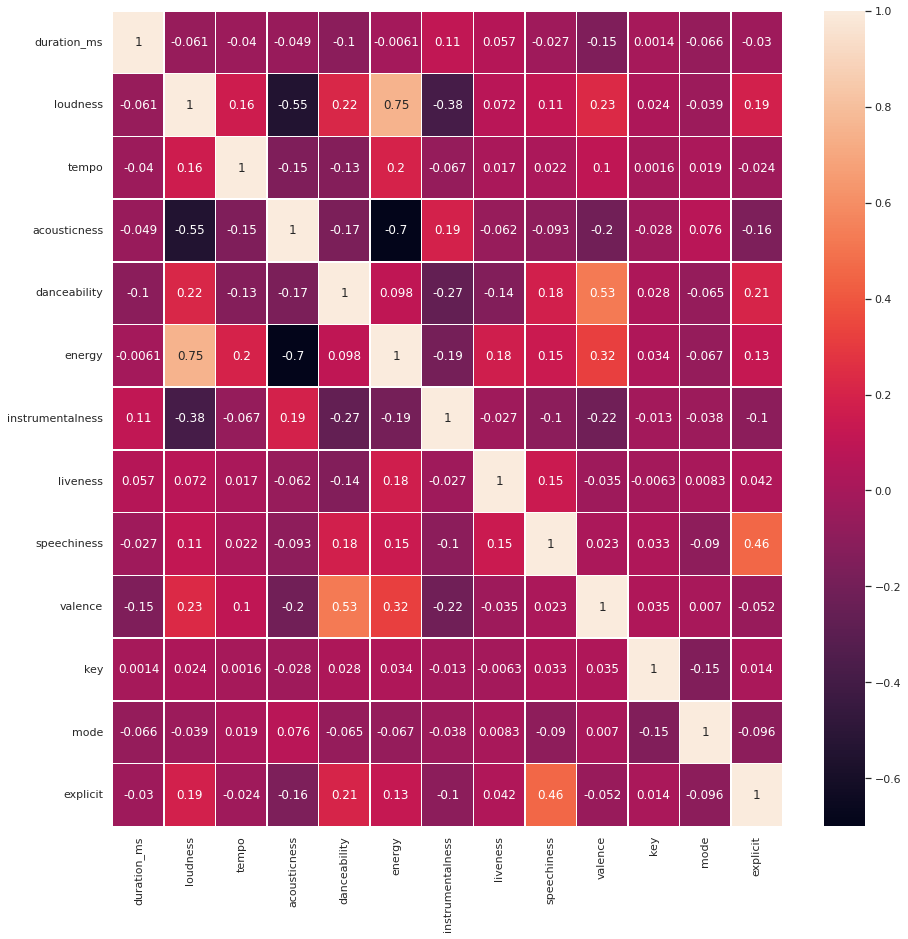

In [ ]:
# find correlations among variables
corr_matrix = df.loc[:,"duration_ms":].corr()
top_correlated_features = corr_matrix.index
plt.figure(figsize = (15,15))
sns.set(style = "whitegrid")
plot = sns.heatmap(corr_matrix, annot = True, linewidths = .5, annot_kws={"size": 12})
# Energy and Acoustiness are highly negatively correlated
# Energy and loudness are highly positively correlated

### **Time Trend**

      billboard  popularity  duration_ms   loudness       tempo  acousticness  \
year                                                                            
1970     0.0045     34.4390  242455.3910 -11.868911  117.228647      0.452995   
1971     0.0475     34.6640  261744.5995 -12.063185  118.234465      0.452908   
1972     0.0625     34.7465  248024.2930 -11.772299  119.249345      0.457333   
1973     0.0505     36.6775  256522.1945 -11.320183  120.419363      0.412537   
1974     0.0445     32.1815  255832.2625 -11.746781  119.827762      0.437784   

      danceability    energy  instrumentalness  liveness  speechiness  \
year                                                                    
1970      0.509339  0.497005          0.125212  0.216363     0.053003   
1971      0.504519  0.500451          0.124619  0.217427     0.061720   
1972      0.520846  0.506952          0.112922  0.209314     0.054874   
1973      0.513551  0.534839          0.104507  0.206505     0.0575

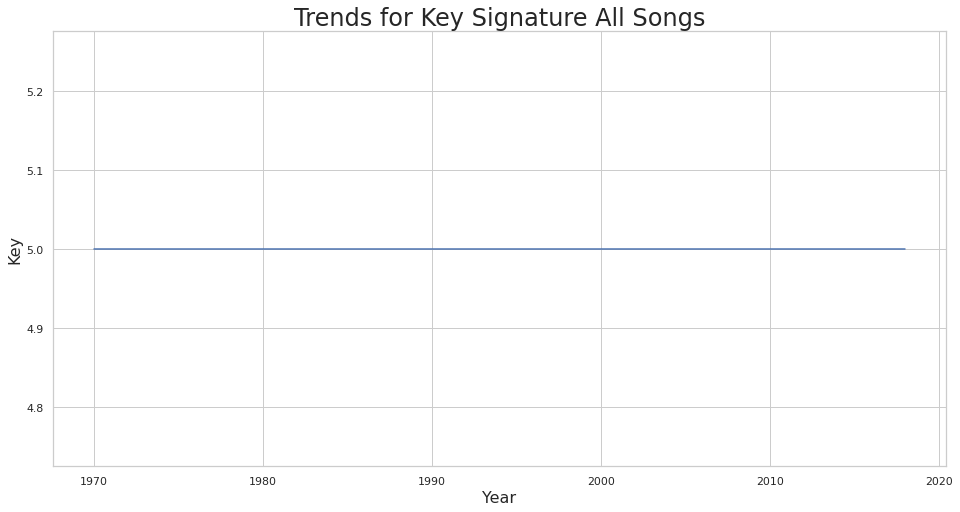

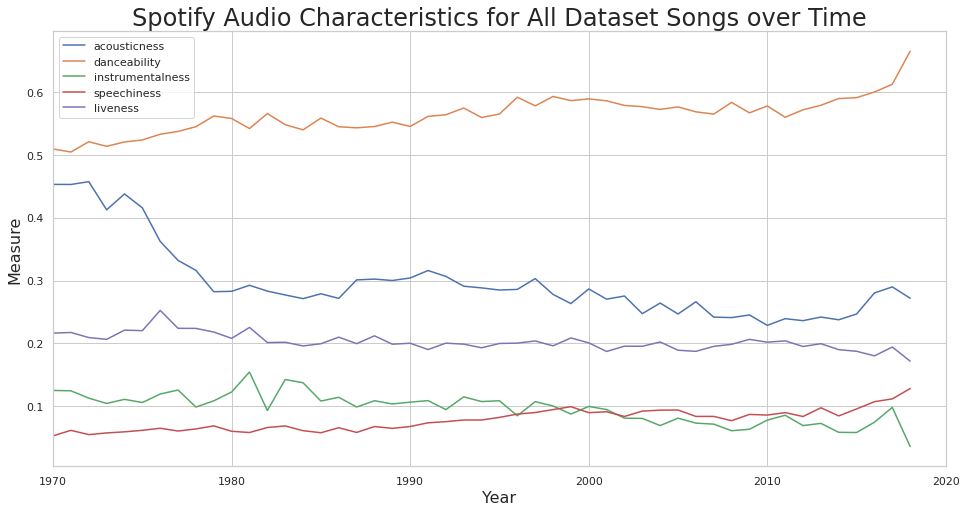

In [ ]:
# time trends of audio features for all songs
trend_allsongs = df.groupby("year").mean()
trend_allsongs["mode"] = np.where(trend_allsongs["mode"] >= .50, 1, 0)
trend_allsongs["explicit"] = np.where(trend_allsongs["explicit"] >= .50, 1, 0)
trend_allsongs["key"] = round(trend_allsongs["key"], 0).astype("int64")

print(trend_allsongs.head())

plt.figure(figsize=(16, 8))
plt.plot(trend_allsongs["key"])
plt.title("Trends for Key Signature All Songs", fontsize=24)
plt.ylabel("Key", fontsize=16)
plt.xlabel("Year", fontsize=16)
plt.show()

plt.figure(figsize=(16, 8))
sns.set(style="whitegrid")
columns = ["acousticness","danceability","instrumentalness","speechiness","liveness"]
for col in columns:
    ax= sns.lineplot(x=trend_allsongs.index,y=trend_allsongs[col],label=col)
ax.set_title('Spotify Audio Characteristics for All Dataset Songs over Time', fontsize=24)
ax.set_ylabel('Measure', fontsize=16)
ax.set_xlabel('Year', fontsize=16)
plt.xlim(1970,2020)
plt.show()

      billboard  popularity    duration_ms   loudness       tempo  \
year                                                                
1970        1.0   41.555556  229082.888889 -10.874000  129.658000   
1971        1.0   44.357895  223251.810526 -10.579526  112.056874   
1972        1.0   43.416000  223031.072000 -11.508040  116.807784   
1973        1.0   44.099010  250492.237624 -11.221040  125.618198   
1974        1.0   40.314607  220284.741573 -10.710045  117.304730   

      acousticness  danceability    energy  instrumentalness  liveness  \
year                                                                     
1970      0.343078      0.544222  0.565000          0.053344  0.280567   
1971      0.372836      0.545653  0.583228          0.063792  0.166856   
1972      0.449611      0.547104  0.527543          0.068561  0.174088   
1973      0.397521      0.544508  0.543920          0.051080  0.144357   
1974      0.394528      0.615202  0.581899          0.025772  0.173397  

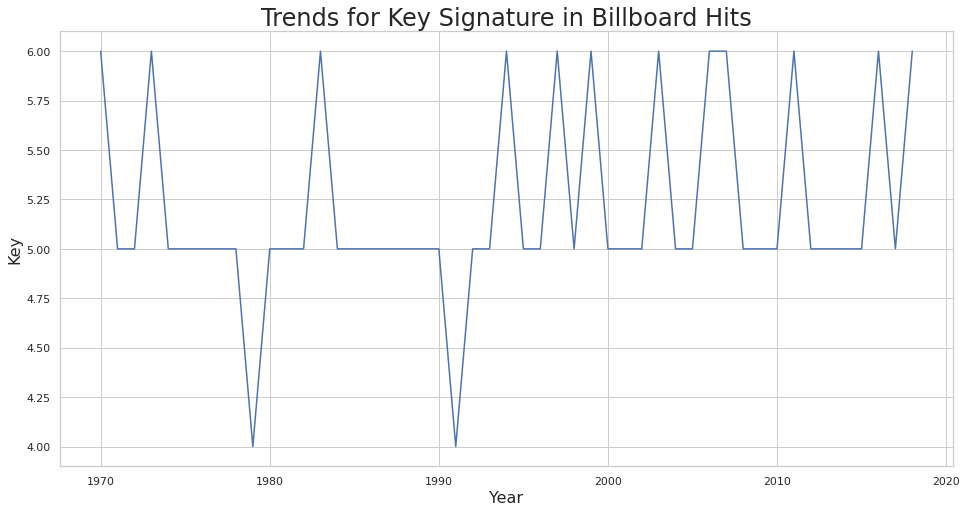

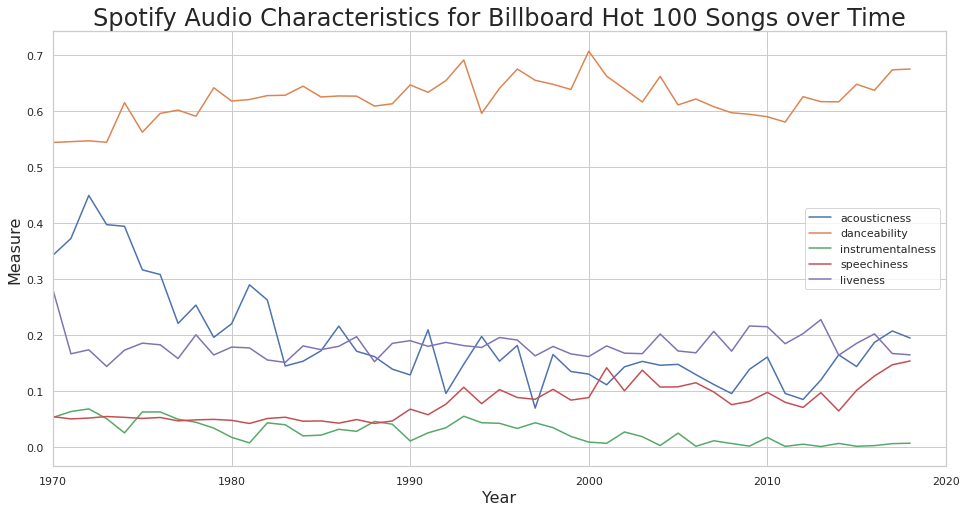

In [ ]:
# time trends of audio features for hits

trend_hits =  df[df["billboard"]==1].groupby("year").mean()
trend_hits["mode"] = np.where(trend_hits["mode"] >= .50, 1, 0)
trend_hits["explicit"] = np.where(trend_hits["explicit"] >= .50, 1, 0)
trend_hits["key"] = round(trend_hits["key"], 0).astype("int64")

print(trend_hits.head())

plt.figure(figsize=(16, 8))
plt.plot(trend_hits["key"])
plt.title("Trends for Key Signature in Billboard Hits", fontsize=24)
plt.ylabel("Key", fontsize=16)
plt.xlabel("Year", fontsize=16)
plt.show()

plt.figure(figsize=(16, 8))
sns.set(style="whitegrid")
columns = ["acousticness","danceability","instrumentalness","speechiness","liveness"]
for col in columns:
    ax= sns.lineplot(x=trend_hits.index,y=trend_hits[col],label=col)
ax.set_title('Spotify Audio Characteristics for Billboard Hot 100 Songs over Time', fontsize=24)
ax.set_ylabel('Measure', fontsize=16)
ax.set_xlabel('Year', fontsize=16)
plt.xlim(1970,2020)
plt.show()

### **Histograms**

array([[<matplotlib.axes._subplots.AxesSubplot object at 0x7f52627859d0>,
      dtype=object)

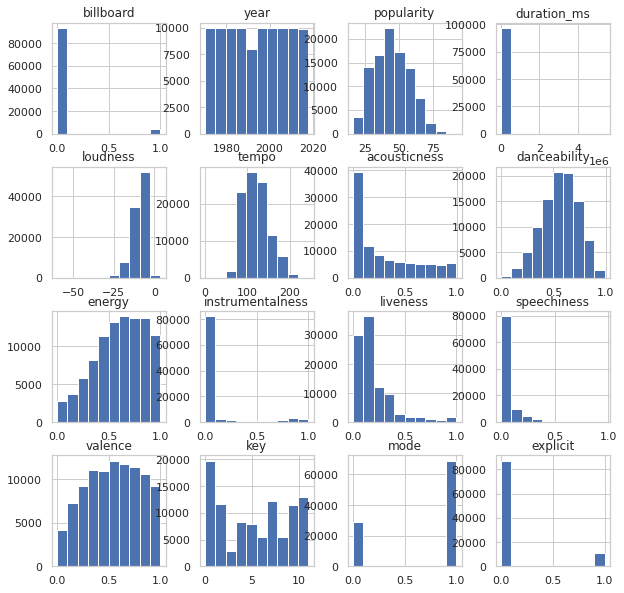

In [ ]:
#histograms of each variable
df.hist(figsize = (10,10))

## **Data Preparation**

### **Exclude Variables**

In [ ]:
# drop the variables
drop_vars = ["popularity", "id", "name", "artists"]  #'year' will be dropped later after joinning the tables
df = df.drop(drop_vars, axis=1)
df.head()

,billboard,year,duration_ms,loudness,tempo,acousticness,danceability,energy,instrumentalness,liveness,speechiness,valence,key,mode,explicit
0,0,1970,380667,-10.884,119.025,0.511,0.436,0.429,0.000103,0.104,0.0319,0.223,3,1,0
1,0,1970,166707,-13.934,76.848,0.465,0.629,0.376,0.000000,0.235,0.0337,0.347,7,1,0
2,0,1970,176573,-10.204,178.408,0.166,0.417,0.753,0.000000,0.269,0.1260,0.794,9,0,0
3,0,1970,141893,-19.189,117.630,0.990,0.600,0.107,0.011400,0.101,0.0525,0.732,0,0,0
4,0,1970,134067,-14.170,147.388,0.639,0.568,0.434,0.626000,0.229,0.0379,0.694,7,1,0


In [ ]:
# drop variables for time trend data
drop_trend_vars = ["billboard","popularity"]
trend_allsongs = trend_allsongs.drop(drop_trend_vars, axis=1)
trend_hits = trend_hits.drop(drop_trend_vars, axis=1)

trend_allsongs.head()

,duration_ms,loudness,tempo,acousticness,danceability,energy,instrumentalness,liveness,speechiness,valence,key,mode,explicit
year,,,,,,,,,,,,,
1970,242455.3910,-11.868911,117.228647,0.452995,0.509339,0.497005,0.125212,0.216363,0.053003,0.574851,5,1,0
1971,261744.5995,-12.063185,118.234465,0.452908,0.504519,0.500451,0.124619,0.217427,0.061720,0.574404,5,1,0
1972,248024.2930,-11.772299,119.249345,0.457333,0.520846,0.506952,0.112922,0.209314,0.054874,0.597264,5,1,0
1973,256522.1945,-11.320183,120.419363,0.412537,0.513551,0.534839,0.104507,0.206505,0.057581,0.587499,5,1,0
1974,255832.2625,-11.746781,119.827762,0.437784,0.520529,0.521902,0.111008,0.221114,0.059337,0.587977,5,1,0


### **Feature Engineering**

In [ ]:
# time trends of audio features for all songs for previous year
prevyear_trend_allsongs = trend_allsongs.copy()
prevyear_trend_allsongs.index = prevyear_trend_allsongs.index +1  #because I compare songs to the previous year trends (need to add 1 to year to join on year)
prevyear_trend_allsongs.head()

,duration_ms,loudness,tempo,acousticness,danceability,energy,instrumentalness,liveness,speechiness,valence,key,mode,explicit
year,,,,,,,,,,,,,
1971,242455.3910,-11.868911,117.228647,0.452995,0.509339,0.497005,0.125212,0.216363,0.053003,0.574851,5,1,0
1972,261744.5995,-12.063185,118.234465,0.452908,0.504519,0.500451,0.124619,0.217427,0.061720,0.574404,5,1,0
1973,248024.2930,-11.772299,119.249345,0.457333,0.520846,0.506952,0.112922,0.209314,0.054874,0.597264,5,1,0
1974,256522.1945,-11.320183,120.419363,0.412537,0.513551,0.534839,0.104507,0.206505,0.057581,0.587499,5,1,0
1975,255832.2625,-11.746781,119.827762,0.437784,0.520529,0.521902,0.111008,0.221114,0.059337,0.587977,5,1,0


In [ ]:
# time trends of audio features for hits for previous year
prevyear_trend_hits = trend_hits.copy()
prevyear_trend_hits.index = prevyear_trend_hits.index +1  #because I compare songs to the previous year trends (need to add 1 to year to join on year)
prevyear_trend_hits.head()

,duration_ms,loudness,tempo,acousticness,danceability,energy,instrumentalness,liveness,speechiness,valence,key,mode,explicit
year,,,,,,,,,,,,,
1971,229082.888889,-10.874000,129.658000,0.343078,0.544222,0.565000,0.053344,0.280567,0.054667,0.738889,6,1,0
1972,223251.810526,-10.579526,112.056874,0.372836,0.545653,0.583228,0.063792,0.166856,0.050702,0.652684,5,1,0
1973,223031.072000,-11.508040,116.807784,0.449611,0.547104,0.527543,0.068561,0.174088,0.052198,0.626704,5,1,0
1974,250492.237624,-11.221040,125.618198,0.397521,0.544508,0.543920,0.051080,0.144357,0.054970,0.644248,6,1,0
1975,220284.741573,-10.710045,117.304730,0.394528,0.615202,0.581899,0.025772,0.173397,0.053465,0.708047,5,1,0


In [ ]:
# left join to get the average song qualities for the previous year and hits the year prior
data = df[df["year"] >= 1971].reset_index(drop=True) # filter out data before 1971 because of missing value limitations
data = data.join(prevyear_trend_allsongs, how="left", on="year", rsuffix="_diff_year")
data = data.join(prevyear_trend_hits, how="left", on="year", rsuffix="_diff_hit_year")
data.head()

,billboard,year,duration_ms,loudness,tempo,acousticness,danceability,energy,instrumentalness,liveness,...,acousticness_diff_hit_year,danceability_diff_hit_year,energy_diff_hit_year,instrumentalness_diff_hit_year,liveness_diff_hit_year,speechiness_diff_hit_year,valence_diff_hit_year,key_diff_hit_year,mode_diff_hit_year,explicit_diff_hit_year
0,0,1971,335013,-10.521,136.110,0.59900,0.775,0.675,0.723000,0.1020,...,0.343078,0.544222,0.565,0.053344,0.280567,0.054667,0.738889,6,1,0
1,0,1971,232507,-10.844,105.965,0.24000,0.354,0.707,0.586000,0.6520,...,0.343078,0.544222,0.565,0.053344,0.280567,0.054667,0.738889,6,1,0
2,0,1971,360413,-14.836,133.555,0.73200,0.458,0.160,0.000038,0.1470,...,0.343078,0.544222,0.565,0.053344,0.280567,0.054667,0.738889,6,1,0
3,0,1971,393960,-5.686,160.719,0.00677,0.388,0.889,0.000233,0.0904,...,0.343078,0.544222,0.565,0.053344,0.280567,0.054667,0.738889,6,1,0
4,0,1971,151933,-14.491,206.088,0.02740,0.510,0.212,0.000043,0.0777,...,0.343078,0.544222,0.565,0.053344,0.280567,0.054667,0.738889,6,1,0


In [ ]:
# get difference between a song and previous year's trend (allsong/hits)

# for numerical variables
numerical_vars = ['duration_ms', 'loudness', 'tempo', 'acousticness', 'danceability','instrumentalness', 'liveness', 'speechiness', 'valence']
for each_var in numerical_vars:
    diff_year_colname = each_var + "_diff_year"
    diff_hit_year_colname = each_var + "_diff_hit_year"
    data[diff_year_colname] = data[each_var] - data[diff_year_colname]           # diff_year metric = song metric - average metric that year
    data[diff_hit_year_colname] = data[each_var] - data[diff_hit_year_colname]    # diff_hit_year metric = song metric - average metric for hits that year

# for binary variables ('mode', 'explicit')
# returns 1 if mode/explicit is the same for yearly trend and the song, 0 otherwise
for each_var in  ["mode", "explicit"]:
    diff_year_colname = each_var + "_diff_year"
    diff_hit_year_colname = each_var + "_diff_hit_year"
    data[diff_year_colname] = np.where(data[each_var].astype("boolean") == data[diff_year_colname].astype("boolean"), 1, 0)
    data[diff_hit_year_colname] = np.where(data[each_var].astype("boolean")== data[diff_hit_year_colname].astype("boolean"), 1, 0)

# for ordinal variables ('key')
# integer subtraction for difference of key for song by year for all songs and hit songs
data["key_diff_year"] = data["key"] - data["key_diff_year"]
data["key_diff_hit_year"] = data["key"] - data["key_diff_hit_year"]

data.head()

,billboard,year,duration_ms,loudness,tempo,acousticness,danceability,energy,instrumentalness,liveness,...,acousticness_diff_hit_year,danceability_diff_hit_year,energy_diff_hit_year,instrumentalness_diff_hit_year,liveness_diff_hit_year,speechiness_diff_hit_year,valence_diff_hit_year,key_diff_hit_year,mode_diff_hit_year,explicit_diff_hit_year
0,0,1971,335013,-10.521,136.110,0.59900,0.775,0.675,0.723000,0.1020,...,0.255922,0.230778,0.565,0.669656,-0.178567,-0.018267,0.143111,3,0,1
1,0,1971,232507,-10.844,105.965,0.24000,0.354,0.707,0.586000,0.6520,...,-0.103078,-0.190222,0.565,0.532656,0.371433,-0.019367,0.005111,2,1,1
2,0,1971,360413,-14.836,133.555,0.73200,0.458,0.160,0.000038,0.1470,...,0.388922,-0.086222,0.565,-0.053305,-0.133567,-0.017067,-0.585889,-3,1,1
3,0,1971,393960,-5.686,160.719,0.00677,0.388,0.889,0.000233,0.0904,...,-0.336308,-0.156222,0.565,-0.053111,-0.190167,0.026733,-0.146889,-6,1,1
4,0,1971,151933,-14.491,206.088,0.02740,0.510,0.212,0.000043,0.0777,...,-0.315678,-0.034222,0.565,-0.053301,-0.202867,0.012133,-0.291889,0,1,1


In [ ]:
#drop year after matching
data = data.drop("year", axis=1)

#checking missing values for final dataset
print(data.isna().sum())

billboard                         0
duration_ms                       0
loudness                          0
tempo                             0
acousticness                      0
danceability                      0
energy                            0
instrumentalness                  0
liveness                          0
speechiness                       0
valence                           0
key                               0
mode                              0
explicit                          0
duration_ms_diff_year             0
loudness_diff_year                0
tempo_diff_year                   0
acousticness_diff_year            0
danceability_diff_year            0
energy_diff_year                  0
instrumentalness_diff_year        0
liveness_diff_year                0
speechiness_diff_year             0
valence_diff_year                 0
key_diff_year                     0
mode_diff_year                    0
explicit_diff_year                0
duration_ms_diff_hit_year   

### **Split Dataset into Train&Test Sets**

In [ ]:
from sklearn.model_selection import train_test_split

# declare X and Y variables
y = data.billboard
X = data.drop("billboard",axis = 1)

print(X.shape)

# split dataset into train&test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

(95900, 39)


### **Dataset Balancing**

Note: I randomly sampled minority instances and repeated until the dataset contains equal number of each class. I perform oversampling in the train set.

In [ ]:
from collections import Counter
from imblearn.over_sampling import RandomOverSampler

In [ ]:
# perform oversampling in the train set

print('Original dataset shape %s' % Counter(y))
print('Train dataset shape %s' % Counter(y_train))
print('Test dataset shape %s' % Counter(y_test))

ros = RandomOverSampler(random_state=42) # default sampling strategy: resample all classes but the majority class
X_oversampled_train, y_oversampled_train = ros.fit_resample(X_train, y_train)

print('Resampled train dataset shape %s' % Counter(y_oversampled_train))

Original dataset shape Counter({0: 91633, 1: 4267})
Train dataset shape Counter({0: 73331, 1: 3389})
Test dataset shape Counter({0: 18302, 1: 878})
Resampled train dataset shape Counter({0: 73331, 1: 73331})


## **Modeling - Logistic Regression**

In [ ]:
# import packages
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn import linear_model
from sklearn import metrics
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
import numpy as np
import os

#To ignore the convergence warnings
from  warnings import simplefilter
from sklearn.exceptions import ConvergenceWarning
simplefilter("ignore", category=ConvergenceWarning)

import math

### **Logistic Regression**

In [ ]:
# Cross Validation
inner_cv = KFold(n_splits = 5, shuffle = True)
outer_cv = KFold(n_splits = 5, shuffle = True)

In [ ]:
# Grid Search
# Choosing C parameter for Logistic Regression AND feature selection
# See other parameters here http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
gs_lr = GridSearchCV(estimator=LogisticRegression(random_state = 42, solver = 'liblinear', multi_class = 'ovr', penalty = 'l1'),
                  param_grid=[{'tol' : [.00001, .0001, .001, .01, .1],
                              'fit_intercept' : [True, False]}],
                  scoring='f1',
                  cv = inner_cv,
                  n_jobs = 4)

In [ ]:
#Fit LR - Key as ordinal variable
lr = gs_lr.fit(X_oversampled_train,y_oversampled_train)  #np.ravel()
print("\n Parameter Tuning")
print("Non-nested CV F-1 Score: ", gs_lr.best_score_)
print("Optimal Parameter: ", gs_lr.best_params_)
print("Optimal Estimator: ", gs_lr.best_estimator_)


 Parameter Tuning
Non-nested CV F-1 Score:  0.6583766836695588
Optimal Parameter:  {'fit_intercept': False, 'tol': 0.01}
Optimal Estimator:  LogisticRegression(fit_intercept=False, multi_class='ovr', penalty='l1',
                   random_state=42, solver='liblinear', tol=0.01)


In [ ]:
nested_score_lr = cross_val_score(gs_lr, X=X_oversampled_train, y=y_oversampled_train, cv=outer_cv, scoring = 'f1')
print("Nested CV F-1 Score:",nested_score_lr.mean(), " +/- ", nested_score_lr.std())

Nested CV F-1 Score: 0.6579495931191152  +/-  0.0008973169160015741


### **Important Features**

In [ ]:
# define LR with optimal parameters
lr =  gs_lr.best_estimator_ #LogisticRegression(fit_intercept=False, multi_class='ovr', penalty='l1',random_state=42, solver='liblinear', tol=0.01)

lr.fit(X_oversampled_train, y_oversampled_train)

LogisticRegression(fit_intercept=False, multi_class='ovr', penalty='l1',
                   random_state=42, solver='liblinear', tol=0.01)

In [ ]:
# get coefficient
lrintercept = lr.intercept_
lrcoefficients = lr.coef_[0]
print(lrintercept)
print(lrcoefficients)

0.0
[-9.32737549e-06 -5.81687950e-03  1.41758440e-02 -5.09092682e-04
  7.62077600e-01 -7.78058985e-02 -8.67201816e-01 -3.80001399e+00
  0.00000000e+00 -1.56029423e+00  5.28363829e-02  3.67138162e-02
  1.26909281e+00  1.19586862e-07 -1.93506731e-01 -1.25103149e-02
 -1.41043153e+00 -5.50549155e+00 -3.38473912e-03 -1.85655565e+00
  1.10933305e+00 -1.22299517e+00  4.55773759e+00 -1.99431431e-01
  2.18620535e-02  5.57461210e-01  9.59498826e-06  2.48076287e-01
 -3.51234305e-04  9.93336718e-02  6.87593670e+00  8.93096580e-01
  5.45952692e-01  1.95507623e+00  7.47771430e-03 -3.28051165e+00
  1.43130884e-01  3.26567805e-02  5.01434322e-01]


In [ ]:
# match odds to column name
feature_importance = pd.DataFrame(X.columns, columns = ["feature"])
feature_importance["odds"] = pow(math.e, lrcoefficients)  # e raised to the power x
feature_importance = feature_importance.sort_values(by = ["odds"], ascending=False)
feature_importance

,feature,odds
30,danceability_diff_hit_year,968.682303
22,valence_diff_year,95.367475
33,liveness_diff_hit_year,7.064458
12,explicit,3.557624
20,liveness_diff_year,3.032335
31,energy_diff_hit_year,2.442682
4,danceability,2.142723
25,explicit_diff_year,1.746234
32,instrumentalness_diff_hit_year,1.726252
38,explicit_diff_hit_year,1.651088


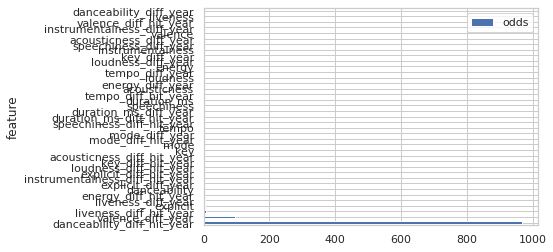

In [ ]:
# draw feature importance graph
ax = feature_importance.plot.barh(x='feature', y='odds')

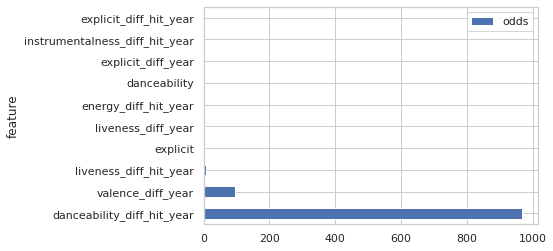

In [ ]:
# draw a graph for top 10 features
selected_top_num = 10
ax2 = feature_importance.head(selected_top_num).plot.barh(x='feature', y='odds')

In [ ]:
feature_importance.head(selected_top_num)["feature"]

30        danceability_diff_hit_year
22                 valence_diff_year
33            liveness_diff_hit_year
12                          explicit
20                liveness_diff_year
31              energy_diff_hit_year
4                       danceability
25                explicit_diff_year
32    instrumentalness_diff_hit_year
38            explicit_diff_hit_year
Name: feature, dtype: object

## **Modeling - k-Nearest Neighbors**

In [ ]:
# import packages
import pandas as pd
import numpy as np
import os
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier # A decision tree classifier
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score #http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
from sklearn.linear_model import LogisticRegression
from sklearn import neighbors, datasets

### **Curse of Dimensionality**

Note: Because of computational efficiency and the Curse of dimensionality, I reduced the dimensionality space by using subset of features.

In [ ]:
drop_cols = ['duration_ms_diff_year', 'loudness_diff_year', 'energy_diff_year',
       'tempo_diff_year', 'acousticness_diff_year', 'danceability_diff_year',
       'instrumentalness_diff_year', 'liveness_diff_year',
       'speechiness_diff_year', 'valence_diff_year', 'key_diff_year',
       'mode_diff_year', 'explicit_diff_year']
X_knn_oversampled_train = X_oversampled_train.drop(drop_cols, axis=1)
X_knn_test = X_test.drop(drop_cols, axis=1)

print(X_knn_oversampled_train.shape)
print(X_knn_test.shape)

(146662, 26)
(19180, 26)


### **Standardization**

In [ ]:
# Standardize features

# X_knn_oversampled_train_std_std: standardized train data
# we cannot standardize nominal variables ('explicit', 'explicit_diff_hit_year', 'mode', 'mode_diff_hit_year')
nominal_vars_train = X_knn_oversampled_train.loc[:, ['explicit', 'explicit_diff_hit_year', 'mode', 'mode_diff_hit_year']]
nominal_vars_test = X_knn_test.loc[:, ['explicit', 'explicit_diff_hit_year', 'mode', 'mode_diff_hit_year']]

print(nominal_vars_train.head())
print(nominal_vars_test.head())

   explicit  explicit_diff_hit_year  mode  mode_diff_hit_year
0         0                       1     0                   0
1         0                       1     1                   1
2         0                       1     1                   1
3         0                       1     1                   1
4         0                       1     1                   1
       explicit  explicit_diff_hit_year  mode  mode_diff_hit_year
71904         0                       1     0                   0
53346         0                       1     1                   1
76372         1                       0     0                   0
42544         0                       1     1                   1
23749         1                       0     0                   0


In [ ]:
X_knn_oversampled_train_std = X_knn_oversampled_train.copy()
X_knn_oversampled_train_std = X_knn_oversampled_train_std.drop(nominal_vars_train.columns, axis=1)
X_knn_train_std_col = X_knn_oversampled_train_std.columns
X_knn_train_std_idx = X_knn_oversampled_train_std.index

X_knn_test_std = X_knn_test.copy()
X_knn_test_std = X_knn_test_std.drop(nominal_vars_test.columns, axis=1)
X_knn_test_std_col = X_knn_test_std.columns
X_knn_test_std_idx = X_knn_test_std.index

print(X_knn_oversampled_train_std.head())
print(X_knn_test_std.head())

   duration_ms  loudness    tempo  acousticness  danceability  energy  \
0       160613    -5.261  175.424        0.2480         0.538   0.607   
1       163192    -6.020  105.983        0.2960         0.877   0.688   
2       204800    -5.309  117.845        0.6400         0.529   0.477   
3       221027    -6.995   76.043        0.1150         0.451   0.669   
4       242333    -6.919  129.978        0.0461         0.772   0.682   

   instrumentalness  liveness  speechiness  valence  ...  \
0          0.000006    0.0999       0.2160    0.515  ...   
1          0.000000    0.3800       0.0432    0.969  ...   
2          0.000005    0.0866       0.0284    0.174  ...   
3          0.000000    0.1050       0.0288    0.399  ...   
4          0.002850    0.0672       0.0701    0.868  ...   

   loudness_diff_hit_year  tempo_diff_hit_year  acousticness_diff_hit_year  \
0                0.411491            51.743364                    0.101546   
1                2.444400           -14.6774

In [ ]:
# standarization
sc1 = StandardScaler()
sc1.fit(X_knn_oversampled_train_std)           # Compute the mean and std to be used for later scaling

X_knn_oversampled_train_std =sc1.transform(X_knn_oversampled_train_std)      #perform standardization of train set
X_knn_test_std = sc1.transform(X_knn_test_std)                               #perform standardization of test set


In [ ]:
# add mode and explicit variables back to X_knn_std
X_knn_oversampled_train_std = pd.concat([pd.DataFrame(X_knn_oversampled_train_std, columns=X_knn_train_std_col, index = X_knn_train_std_idx), nominal_vars_train], axis=1)
X_knn_test_std = pd.concat([pd.DataFrame(X_knn_test_std, columns=X_knn_test_std_col, index=X_knn_test_std_idx), nominal_vars_test], axis=1)

In [ ]:
X_knn_oversampled_train_std.head()

,duration_ms,loudness,tempo,acousticness,danceability,energy,instrumentalness,liveness,speechiness,valence,...,energy_diff_hit_year,instrumentalness_diff_hit_year,liveness_diff_hit_year,speechiness_diff_hit_year,valence_diff_hit_year,key_diff_hit_year,explicit,explicit_diff_hit_year,mode,mode_diff_hit_year
0,-0.990004,0.798613,1.882777,0.015799,-0.325682,-0.126133,-0.318884,-0.561403,1.493625,-0.192254,...,1.008846,-0.197245,-0.673919,1.186954,-0.155379,1.101282,0,1,0,0
1,-0.959425,0.624449,-0.523430,0.191583,1.754381,0.243420,-0.318913,1.127413,-0.394356,1.638792,...,-0.415081,-0.410005,1.143846,-0.412553,1.931091,0.822568,0,1,1,1
2,-0.466077,0.787599,-0.112399,1.451369,-0.380905,-0.719242,-0.318890,-0.641593,-0.556058,-1.567555,...,-0.403975,-0.363817,-0.620815,-0.863989,-1.384653,-1.128431,0,1,1,1
3,-0.273673,0.400721,-1.560884,-0.471269,-0.859504,0.156734,-0.318913,-0.530653,-0.551688,-0.660098,...,0.864952,-0.188351,-0.797183,-0.793269,-0.315358,1.101282,0,1,1,1
4,-0.021047,0.418160,0.308023,-0.723593,1.110113,0.216045,-0.304113,-0.758562,-0.100452,1.231445,...,0.637395,-0.394667,-0.636090,-0.199332,1.371361,1.101282,0,1,1,1


In [ ]:
X_knn_test_std.head()

,duration_ms,loudness,tempo,acousticness,danceability,energy,instrumentalness,liveness,speechiness,valence,...,energy_diff_hit_year,instrumentalness_diff_hit_year,liveness_diff_hit_year,speechiness_diff_hit_year,valence_diff_hit_year,key_diff_hit_year,explicit,explicit_diff_hit_year,mode,mode_diff_hit_year
71904,-1.981608,-1.379008,-0.591450,2.282681,0.815591,-1.376225,-0.317683,-0.569241,3.930082,-0.619767,...,-0.941169,-0.214023,-0.473789,3.233365,-0.083559,-1.128431,0,1,0,0
53346,0.098792,0.099663,0.144123,1.491653,-1.448548,-0.842426,-0.206745,0.180808,-0.562614,-1.708715,...,-1.469383,-0.397400,0.159248,-0.290197,-1.962721,0.543854,0,1,1,1
76372,-0.059061,1.309861,0.932783,-0.891931,-1.258336,1.406826,-0.318913,-0.604211,1.154924,-0.647999,...,0.864952,-0.188351,-0.870111,0.951622,-0.303006,-0.013574,1,0,0,0
42544,0.573868,-0.195199,0.481729,-0.645222,1.263510,-0.833302,3.087690,-0.609638,-0.456633,-1.353799,...,1.406320,3.229994,-0.618098,-0.503557,-0.975375,-1.128431,0,1,1,1
23749,-0.170126,1.022112,0.726539,-0.768637,-0.491351,1.101147,-0.318913,2.725186,-0.498151,-1.095678,...,0.303801,-0.190734,2.684222,-0.784861,-0.780858,1.658710,1,0,0,0


### **kNN**

In [ ]:
# Cross Validation
inner_cv = KFold(n_splits=5, shuffle=True)
outer_cv = KFold(n_splits=5, shuffle=True)

In [ ]:
# GridSearchCV performs an exhaustive search over specified parameter values for an estimator
# The parameters of the estimator used to apply these methods are optimized by cross-validated grid-search over a parameter grid.

gs_knn = GridSearchCV(estimator=neighbors.KNeighborsClassifier(metric='minkowski'),
                      param_grid=[{'n_neighbors': [3,5,7,9,13,17,21],
                                    'weights':['uniform','distance'],
                                    'p': [1,2]}],
                      scoring='f1',
                      cv=inner_cv,
                      n_jobs = 4)

In [ ]:
# standardized data & key as ordinal variable
knn_std = gs_knn.fit(X_knn_oversampled_train_std,y_oversampled_train)
print("\n Standardized k-NN Parameter Tuning")
print("Non-nested CV F1: ", knn_std.best_score_)
print("Optimal Parameter: ", knn_std.best_params_)
print("Optimal Estimator: ", knn_std.best_estimator_)

/usr/local/lib/python3.7/dist-packages/joblib/externals/loky/process_executor.py:705: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  "timeout or by a memory leak.", UserWarning



 Standardized k-NN Parameter Tuning
Non-nested CV F1:  0.950845354086549
Optimal Parameter:  {'n_neighbors': 3, 'p': 1, 'weights': 'distance'}
Optimal Estimator:  KNeighborsClassifier(n_neighbors=3, p=1, weights='distance')


In [ ]:
nested_score_knn_std = cross_val_score(gs_knn, X=X_knn_oversampled_train_std, y=y_oversampled_train, cv=outer_cv)
print("Nested CV F1: ",nested_score_knn_std.mean(), " +/- ", nested_score_knn_std.std())

/usr/local/lib/python3.7/dist-packages/joblib/externals/loky/process_executor.py:705: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  "timeout or by a memory leak.", UserWarning
/usr/local/lib/python3.7/dist-packages/joblib/externals/loky/process_executor.py:705: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  "timeout or by a memory leak.", UserWarning


Nested CV F1:  0.949760462159871  +/-  0.0006611967225585502


## **Modeling - Decision Tree**

In [ ]:
# import packages
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV,KFold
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

from sklearn.tree import export_graphviz
import pydot
from IPython.display import Image

from matplotlib import pyplot

### **Decision Tree**

In [ ]:
# Cross Validation
inner_cv = KFold(n_splits = 5, shuffle = True)
outer_cv = KFold(n_splits = 5, shuffle = True)

In [ ]:
# Grid Search
gs_dt = GridSearchCV(estimator=DecisionTreeClassifier(random_state=42),
                  param_grid=[{'max_depth': [7,8,9,10,11,12,13,14,15,16,None],
                               'min_samples_split':[2,3,4,5,6,7,8],
                               'criterion':['gini', 'entropy'],
                               'max_features':['auto', 'sqrt', 'log2'],
                               }],
                  scoring='f1',
                  cv=inner_cv,
                  n_jobs=4)

In [ ]:
# Fit DT - Key as ordinal variable
gs_dt = gs_dt.fit(X_oversampled_train,y_oversampled_train)
print("\n Parameter Tuning: Decision Tree")
print("Non-nested CV Recall: ", gs_dt.best_score_)
print("Optimal Parameter: ", gs_dt.best_params_)
print("Optimal Estimator: ", gs_dt.best_estimator_)


 Parameter Tuning: Decision Tree
Non-nested CV Recall:  0.9764971988671786
Optimal Parameter:  {'criterion': 'gini', 'max_depth': None, 'max_features': 'auto', 'min_samples_split': 8}
Optimal Estimator:  DecisionTreeClassifier(max_features='auto', min_samples_split=8,
                       random_state=42)


In [ ]:
nested_score_dt = cross_val_score(gs_dt, X=X_oversampled_train, y=y_oversampled_train, cv=outer_cv)
print("Nested CV Recall: ",nested_score_dt.mean(), " +/- ", nested_score_dt.std())

Nested CV Recall:  0.9760030676878158  +/-  0.0004614459136740186


### **Visualization**

In [ ]:
# Define path of an image
# Function that takes as input fig_id and returns back the image path
PROJECT_ROOT_DIR = "."

def image_path(fig_id):
    return os.path.join(PROJECT_ROOT_DIR, fig_id)

def save_fig(fig_id, tight_layout=True):
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(image_path(fig_id) + ".png", format='png', dpi=2400)

def export_dot(tree_classifier, file_name):
    try:
        export_graphviz(
            tree_classifier,
            out_file=image_path(file_name),
            feature_names=main.columns[0:-1],
            class_names=y.name,
            rounded=True,
            filled=True
        )
        print("Successfully exported .dot file.")
    except:
        print("Error in exporting .dot file.")

In [ ]:
# define DT with optimal parameters
tree =  gs_dt.best_estimator_  #DecisionTreeClassifier(max_features='auto', min_samples_split=8, random_state=42)

tree.fit(X_oversampled_train,y_oversampled_train)

DecisionTreeClassifier(max_features='auto', min_samples_split=8,
                       random_state=42)

In [ ]:
export_graphviz(
        tree,
        out_file=image_path("best_tree.dot"),
        feature_names=X.columns,
        class_names=y.name,
        rounded=True,
        filled=True)
(graph,) = pydot.graph_from_dot_file(image_path("best_tree.dot"))
graph.write_png(image_path('best_tree.png'))
Image(filename=image_path("best_tree.png"))

### **Important Features**

In [ ]:
# get importance as dictionary
importance = tree.feature_importances_

important_features_dict = dict()
for i,v in enumerate(importance):
    important_features_dict[i] = v

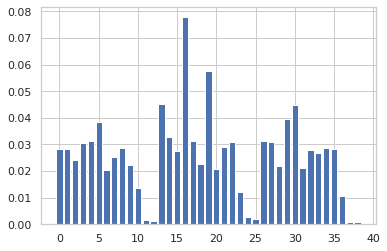

In [ ]:
# plot feature importance
pyplot.bar([x for x in range(len(importance))], importance)
pyplot.show()

In [ ]:
# get top 10 features
selected_num = 10

# sort by importance
sorted_importance_indices = np.argsort(importance)[::-1]
colname = X.columns

top_selected_important_indices = sorted_importance_indices[:selected_num]

top_selected_importance = dict()
importance_rank = 0
for importance_i in top_selected_important_indices:
    importance_rank+=1
    top_selected_importance[importance_i] = importance[importance_i]
    print("{feature}th variable is important as {importance_rank}, column name is {colname}, importance value is {importance}".format(
    feature = importance_i,
        importance_rank = importance_rank,
        colname = colname[importance_i],
        importance = importance[importance_i]
    ))

16th variable is important as 1, column name is acousticness_diff_year, importance value is 0.07781945242880942
19th variable is important as 2, column name is instrumentalness_diff_year, importance value is 0.057460078229495365
13th variable is important as 3, column name is duration_ms_diff_year, importance value is 0.045173436452695115
30th variable is important as 4, column name is danceability_diff_hit_year, importance value is 0.044862503837431546
29th variable is important as 5, column name is acousticness_diff_hit_year, importance value is 0.03968664254918856
5th variable is important as 6, column name is energy, importance value is 0.03849079281056899
14th variable is important as 7, column name is loudness_diff_year, importance value is 0.03272068844405884
17th variable is important as 8, column name is danceability_diff_year, importance value is 0.03134837967805878
26th variable is important as 9, column name is duration_ms_diff_hit_year, importance value is 0.03124288657025


## **Evaluation**

In [ ]:
import pandas as pd
import numpy as np
import os
from sklearn import neighbors, linear_model,metrics
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score, f1_score, cohen_kappa_score,  confusion_matrix, classification_report, auc,roc_curve
from sklearn.model_selection import train_test_split, KFold, cross_val_score,learning_curve, ShuffleSplit, StratifiedKFold, validation_curve, GridSearchCV
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

### **Build Classifiers with Optimal Parameters**

In [ ]:
clf_lr = LogisticRegression(fit_intercept=False, multi_class='ovr', penalty='l1',random_state=42, solver='liblinear', tol=0.01)
clf_knn = KNeighborsClassifier(n_neighbors=3, p=1, weights='distance')
clf_dt = DecisionTreeClassifier(max_features='auto', min_samples_split=8, random_state=42)

# clf_lr = gs_lr.best_estimator_        # LogisticRegression(fit_intercept=False, multi_class='ovr', penalty='l1',random_state=42, solver='liblinear', tol=0.01)
# clf_knn = gs_knn.best_estimator_  # KNeighborsClassifier(n_neighbors=3, p=1, weights='distance')
# clf_dt = gs_dt.best_estimator_        # DecisionTreeClassifier(max_features='auto', min_samples_split=8, random_state=42)

In [ ]:
# random permutations cross-validation
cv = ShuffleSplit(n_splits=10, test_size=0.20, random_state=42)

### **Performance Metrics & Classification Report**

In [ ]:
# https://scikit-learn.org/stable/modules/classes.html#sklearn-metrics-metrics
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, classification_report

In [ ]:
# Estimate the predicted values
lr_y_pred = clf_lr.fit(X_oversampled_train,y_oversampled_train).predict(X_test)
lr_y_pred_insample = clf_lr.fit(X_oversampled_train,y_oversampled_train).predict(X_oversampled_train)

# Accuracy
print('Accuracy (out-of-sample): %.2f' % accuracy_score(y_test, lr_y_pred))
print('Accuracy (in-sample): %.2f' % accuracy_score(y_oversampled_train, lr_y_pred_insample))

# F1 score
print('F1 score (out-of-sample): ', f1_score(y_test, lr_y_pred, average='macro'))           # average='macro' calculate metrics for each label, and find their unweighted mean
print('F1 score (in-sample)    : ', f1_score(y_oversampled_train, lr_y_pred_insample, average='macro')) # this macro value does not take label imbalance into account.

# Kappa score
print('Kappa score (out-of-sample): ', cohen_kappa_score(y_test, lr_y_pred))                # computes Cohen’s kappa: a statistic that measures inter-annotator agreement
print('Kappa score (in-sample)    : ', cohen_kappa_score(y_oversampled_train, lr_y_pred_insample))      # (i.e., agreement between predictions and actual values of target variables)

# Build a text report showing the main classification metrics (out-of-sample performance)
print(classification_report(y_test, lr_y_pred))             # builds a text report showing the main classification metrics (precision, recall, f1-score)

Accuracy (out-of-sample): 0.57
Accuracy (in-sample): 0.63
F1 score (out-of-sample):  0.4207542781796769
F1 score (in-sample)    :  0.6331131990284151
Kappa score (out-of-sample):  0.04773188563890696
Kappa score (in-sample)    :  0.2699267703972399
              precision    recall  f1-score   support

           0       0.97      0.56      0.71     18302
           1       0.07      0.68      0.13       878

    accuracy                           0.57     19180
   macro avg       0.52      0.62      0.42     19180
weighted avg       0.93      0.57      0.69     19180



In [ ]:
# Estimate the predicted values
knn_y_pred = clf_knn.fit(X_knn_oversampled_train_std,y_oversampled_train) .predict(X_knn_test_std)
knn_y_pred_insample = clf_knn.fit(X_knn_oversampled_train_std,y_oversampled_train) .predict(X_knn_oversampled_train_std)

# Accuracy
print('Accuracy (out-of-sample): %.2f' % accuracy_score(y_test, knn_y_pred))
print('Accuracy (in-sample): %.2f' % accuracy_score(y_oversampled_train, knn_y_pred_insample))

# F1 score
print('F1 score (out-of-sample): ', f1_score(y_test, knn_y_pred, average='macro'))           # average='macro' calculate metrics for each label, and find their unweighted mean
print('F1 score (in-sample)    : ', f1_score(y_oversampled_train, knn_y_pred_insample, average='macro')) # this macro value does not take label imbalance into account.

# Kappa score
print('Kappa score (out-of-sample): ', cohen_kappa_score(y_test, knn_y_pred))                # computes Cohen’s kappa: a statistic that measures inter-annotator agreement
print('Kappa score (in-sample)    : ', cohen_kappa_score(y_oversampled_train, knn_y_pred_insample))      # (i.e., agreement between predictions and actual values of target variables)

# Build a text report showing the main classification metrics (out-of-sample performance)
print(classification_report(y_test, knn_y_pred))             # builds a text report showing the main classification metrics (precision, recall, f1-score)

Accuracy (out-of-sample): 0.88
Accuracy (in-sample): 1.00
F1 score (out-of-sample):  0.5375284300662881
F1 score (in-sample)    :  0.999986363202463
Kappa score (out-of-sample):  0.08264431577134645
Kappa score (in-sample)    :  0.9999727264049311
              precision    recall  f1-score   support

           0       0.96      0.91      0.94     18302
           1       0.10      0.21      0.14       878

    accuracy                           0.88     19180
   macro avg       0.53      0.56      0.54     19180
weighted avg       0.92      0.88      0.90     19180



In [ ]:
# Estimate the predicted values
dt_y_pred = clf_dt.fit(X_oversampled_train,y_oversampled_train).predict(X_test)
dt_y_pred_insample = clf_dt.fit(X_oversampled_train,y_oversampled_train).predict(X_oversampled_train)

# Accuracy
print('Accuracy (out-of-sample): %.2f' % accuracy_score(y_test, dt_y_pred))
print('Accuracy (in-sample): %.2f' % accuracy_score(y_oversampled_train, dt_y_pred_insample))

# F1 score
print('F1 score (out-of-sample): ', f1_score(y_test, dt_y_pred, average='macro'))           # average='macro' calculate metrics for each label, and find their unweighted mean
print('F1 score (in-sample)    : ', f1_score(y_oversampled_train, dt_y_pred_insample, average='macro')) # this macro value does not take label imbalance into account.

# Kappa score
print('Kappa score (out-of-sample): ', cohen_kappa_score(y_test, dt_y_pred))                # computes Cohen’s kappa: a statistic that measures inter-annotator agreement
print('Kappa score (in-sample)    : ', cohen_kappa_score(y_oversampled_train, dt_y_pred_insample))      # (i.e., agreement between predictions and actual values of target variables)

# Build a text report showing the main classification metrics (out-of-sample performance)
print(classification_report(y_test, dt_y_pred))             # builds a text report showing the main classification metrics (precision, recall, f1-score)

Accuracy (out-of-sample): 0.92
Accuracy (in-sample): 1.00
F1 score (out-of-sample):  0.5454345701391505
F1 score (in-sample)    :  0.999986363202463
Kappa score (out-of-sample):  0.09090548561056744
Kappa score (in-sample)    :  0.9999727264049311
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     18302
           1       0.14      0.13      0.13       878

    accuracy                           0.92     19180
   macro avg       0.55      0.54      0.55     19180
weighted avg       0.92      0.92      0.92     19180



### **Confusion Matrix**

In [ ]:
from sklearn.metrics import confusion_matrix           # confusion_matrix will help us compute confusion matrix
import itertools
import matplotlib.pyplot as plt

In [ ]:
# Function that prints and plots the confusion matrix.
# Normalization can be applied by setting `normalize=True` (see below for examples)
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] # devide absolute number of observations with sum across columns to get the relative percentage of observations
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)         # shows the confusion matrix in the console
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))                       # add tick marks to the confusion matrix
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'                          # choose format depending on whether the confusion matrix is normalizaed or not
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])): # loop that adds the value to each cell of the confusion matrix
        plt.text(j, i, format(cm[i, j], fmt),                              # we reformat how the cell values are displayed accroding to the variable fmt we defined before
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

Confusion matrix, without normalization
[[10332  7970]
 [  279   599]]


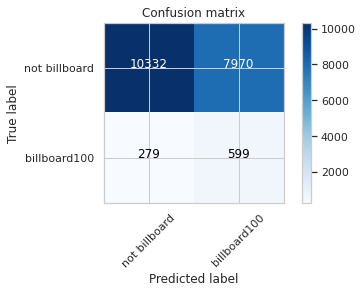

In [ ]:
lr_y_pred = clf_lr.fit(X_oversampled_train,y_oversampled_train).predict(X_test)
np.set_printoptions(precision=2)
plt.figure()
plot_confusion_matrix(confusion_matrix(y_test, lr_y_pred), classes= ['not billboard', 'billboard100'], title='Confusion matrix')
plt.show()

Confusion matrix, without normalization
[[16724  1578]
 [  695   183]]


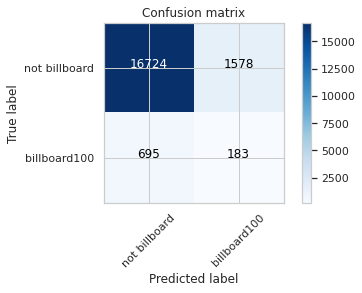

In [ ]:
knn_y_pred = clf_knn.fit(X_knn_oversampled_train_std,y_oversampled_train) .predict(X_knn_test_std)
np.set_printoptions(precision=2)
plt.figure()
plot_confusion_matrix(confusion_matrix(y_test, knn_y_pred), classes= ['not billboard', 'billboard100'], title='Confusion matrix')
plt.show()

Confusion matrix, without normalization
[[17586   716]
 [  766   112]]


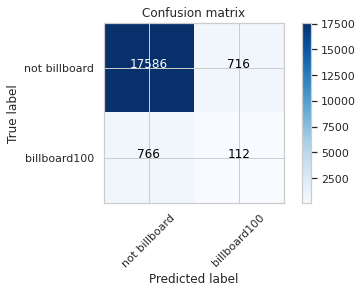

In [ ]:
dt_y_pred = clf_dt.fit(X_oversampled_train,y_oversampled_train).predict(X_test)
np.set_printoptions(precision=2)
plt.figure()
plot_confusion_matrix(confusion_matrix(y_test, dt_y_pred), classes= ['not billboard', 'billboard100'], title='Confusion matrix')
plt.show()

### **Learning Curves**

In [ ]:
### Function for Learning Curves
def plot_learning_curve(estimator, title, X, y, scoring_method, ylim=None, cv=None,
                        n_jobs=1, train_sizes=np.linspace(.1, 1.0, 10)):
    plt.figure()                    #display figure
    plt.title(title)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.xlabel("Training examples") #y label title
    plt.ylabel(scoring_method)             #x label title

    # Class learning_curve determines cross-validated training and test scores for different training set sizes
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, scoring = scoring_method, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes,random_state =42)

    # Cross validation statistics for training and testing data (mean and standard deviation)
    train_scores_mean = np.mean(train_scores, axis=1) # Compute the arithmetic mean along the specified axis.
    train_scores_std = np.std(train_scores, axis=1)   # Compute the standard deviation along the specified axis.
    test_scores_mean = np.mean(test_scores, axis=1)   # Compute the arithmetic mean along the specified axis.
    test_scores_std = np.std(test_scores, axis=1)     # Compute the standard deviation along the specified axis.

    plt.grid() # Configure the grid lines

    # Fill the area around the line to indicate the size of standard deviations for the training data
    # and the test data
    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1,
                     color="r") # train data performance indicated with red
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g") # test data performance indicated with green

    # Cross-validation means indicated by dots
    # Train data performance indicated with red
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r",
             label="Training score")
    # Test data performance indicated with green
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g",
             label="Cross-validation score")

    plt.legend(loc="best") # Show legend of the plot at the best location possible
    return plt             # Function that returns the plot as an output

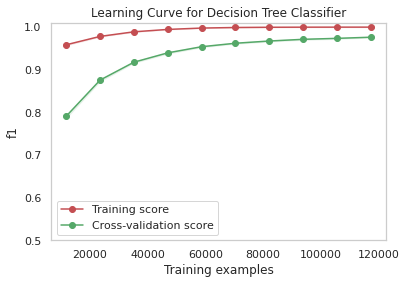

In [ ]:
# Learning Curve: Decision Tree Classifier
plot_learning_curve(clf_dt, "Learning Curve for Decision Tree Classifier", X_oversampled_train, y_oversampled_train, 'f1',(0.50, 1.01), cv=cv, n_jobs=4)
plt.show()

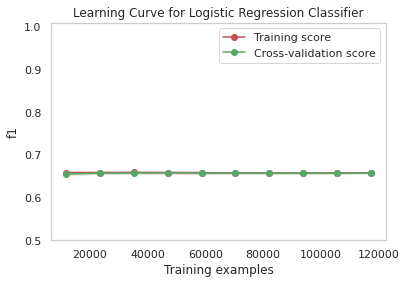

In [ ]:
# Learning Curve: Logistic Regression Classifier
plot_learning_curve(clf_lr, "Learning Curve for Logistic Regression Classifier", X_oversampled_train, y_oversampled_train, 'f1',(0.50, 1.01), cv=cv, n_jobs=4)
plt.show()

/usr/local/lib/python3.7/dist-packages/joblib/externals/loky/process_executor.py:705: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  "timeout or by a memory leak.", UserWarning


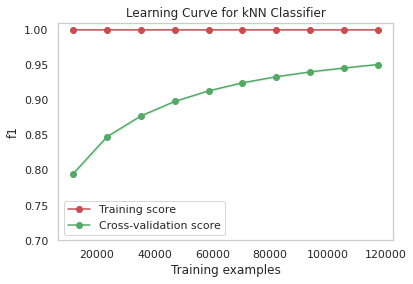

In [ ]:
# Learning Curve: kNN Classifier
plot_learning_curve(clf_knn, "Learning Curve for kNN Classifier", X_knn_oversampled_train_std, y_oversampled_train, 'f1',(0.70, 1.01), cv=cv, n_jobs=4)
plt.show()

### **Fitting Graphs**

In [ ]:
# Function for fitting graphs
def plot_fitting_curve(estimator, title, X, y,param_name,param_range,scoring_method, ylim=None, cv=None,
                        n_jobs=1):

    plt.figure()
    plt.grid()
    plt.title(title)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.xlabel("Parameter "+param_name)
    plt.ylabel(scoring_method)

    train_scores, test_scores = validation_curve(estimator=estimator, X=X,y=y,param_name=param_name, param_range=param_range,cv=cv,scoring=scoring_method,n_jobs=4)
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)

    plt.plot(param_range, train_mean, color='blue', marker='o',markersize=5, label='training f1-score')
    plt.fill_between(param_range, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')

    plt.plot(param_range, test_mean,color='green', linestyle='--', marker='s', markersize=5, label='validation f1-score')
    plt.fill_between(param_range,test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')

    plt.legend(loc='best')
    plt.tight_layout()
    return plt

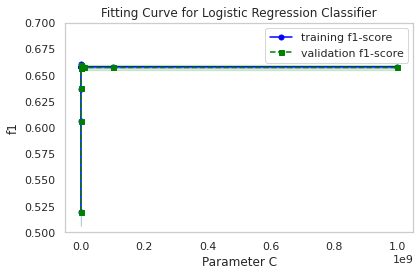

In [ ]:
# Fitting Graph: Logistic Regression Classifier
param_range = [0.00001, 0.0001, 0.001, 0.01, 0.1 ,1 ,10 ,100, 1000, 10000, 100000, 1000000, 10000000, 100000000, 1000000000]
plot_fitting_curve(clf_lr, "Fitting Curve for Logistic Regression Classifier", X_oversampled_train, y_oversampled_train,
                   'C', param_range,'f1', ylim=[0.5,0.7], cv=cv, n_jobs=4)
plt.show()

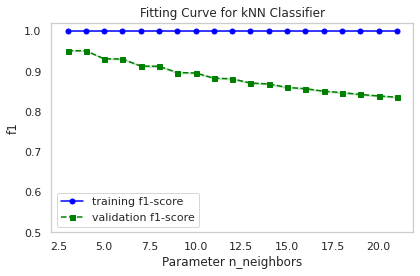

In [ ]:
# Fitting Graph: kNN Classifier

param_range = [i for i in range(3,22)]
plot_fitting_curve(clf_knn, "Fitting Curve for kNN Classifier", X_knn_oversampled_train_std, y_oversampled_train,
                   'n_neighbors', param_range,'f1', ylim=[0.5,1.02], cv=cv, n_jobs=4)
plt.show()

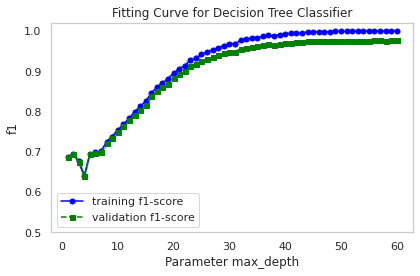

In [ ]:
# Fitting Graph: Decision Tree Classifier
param_range = [i for i in range(1,61)]
plot_fitting_curve(clf_dt, "Fitting Curve for Decision Tree Classifier", X_oversampled_train, y_oversampled_train,
                   'max_depth',param_range,'f1', ylim=[0.5,1.02], cv=cv, n_jobs=4)
plt.show()

### **ROC Curves**

In [ ]:
# Function for ROC curves
def plot_ROC_curve(clf, label, clr, ls, X_train, X_test, y_train, y_test):
    y_pred = clf.fit(X_train, y_train).predict_proba(X_test)[:, 1] # Make predictions based on the classifiers
    fpr, tpr, thresholds = roc_curve(y_true=y_test, # Build ROC curve
                                     y_score=y_pred)
    roc_auc = auc(x=fpr, y=tpr)                # Compute Area Under the Curve (AUC)
    plt.plot(fpr, tpr,                         # Plot ROC Curve and create label with AUC values
             color=clr,
             linestyle=ls,
             label='%s (auc = %0.2f)' % (label, roc_auc))
    return plt

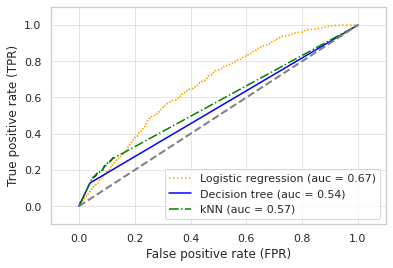

In [ ]:
# Draw ROC Curves

#LR
plot_ROC_curve(clf_lr, label='Logistic regression', clr='orange', ls=':', X_train=X_oversampled_train, X_test=X_test, y_train=y_oversampled_train, y_test=y_test)
#DT
plot_ROC_curve(clf_dt, label='Decision tree', clr='blue', ls='-', X_train=X_oversampled_train, X_test=X_test, y_train=y_oversampled_train, y_test=y_test)
#kNN
plot_ROC_curve(clf_knn, label='kNN', clr='green', ls='-.', X_train=X_knn_oversampled_train_std, X_test=X_knn_test_std, y_train=y_oversampled_train, y_test=y_test)

plt.legend(loc='lower right')    # Where to place the legend
plt.plot([0, 1], [0, 1], # Visualize random classifier
         linestyle='--',
         color='gray',
         linewidth=2)

plt.xlim([-0.1, 1.1])   #limits for x axis
plt.ylim([-0.1, 1.1])   #limits for y axis
plt.grid(alpha=0.5)
plt.xlabel('False positive rate (FPR)')
plt.ylabel('True positive rate (TPR)')

#plt.savefig('ROC_all_classifiers', dpi=300)
plt.show()